# Linear algebra with Python: from forces to a temperature field
### A guided computational case study for beginning engineers

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 17 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/17_Linear_Algebra_for_Engineers.ipynb)

This notebook introduces vectors, matrices, matrix products, linear systems, eigensystems, and the elementary use of least squares. The central engineering example predicts temperatures along a bar at steady state. It assumes only arithmetic, simple algebra, Newtonian force components, and the introductory Python of notebooks 01–05. The mathematics is developed *before* the corresponding Python instruction.

This is a **self-study example**. Work from top to bottom with **Run All**. A Jupyter notebook (`.ipynb`) can be opened in JupyterLab or Jupyter Notebook supplied through Anaconda. Install the two additional packages if necessary with `python -m pip install numpy matplotlib`. A code cell can also be copied to Spyder, but the explanations and saved figures are part of this notebook.

### How to study this notebook

1. Read the model and predict a simple result **before** running its code cell. Work out small matrix products on paper when possible.
2. Run one cell and compare its printed values or figure with your prediction. A nearby comment explains each executable line; pay attention to *why* a shape check, loop boundary, or numerical tolerance is used.
3. Change one input at a time in a copy of the notebook, rerun the affected cells, and use the assertions to diagnose surprises. If a check fails, inspect the shapes, units, and error message before changing the tolerance.
4. Complete the independent practice questions, then run the answer cell and read the interpretations. The power-iteration, least-squares, and elimination sections are optional extensions.

A printed result is not proof that a physical model is correct. The hand calculations, residuals, boundary cases, and model assumptions provide different kinds of checks. The notebook runs top to bottom with **Run All** when left unmodified.


<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 6, Engineering practice |
| **Time** | about 55 min (about 110 min with exercises) |
| **Before this** | Lists and nested loops (notebooks 02–04); NumPy arrays (notebook 05). |
| **Essential** | Sections 1–5, up to and including "Find and fix a row-versus-column bug", and the practice in Section 8. |
| **Optional on a first reading** | Power iteration (end of Section 5), Sections 6 and 7 (fitting, numerical cautions, explicit elimination). |
| **Next** | The extensions, 18–22, in any order. |

**You have understood this notebook if you can, without looking back:**

1. Compute a dot product and a matrix–vector product with loops and with `@`, and check that the two agree.
2. Write the steady temperature of a bar as A T = b, and solve it with `np.linalg.solve`.
3. Change the end temperatures or the number of nodes, and predict the result before running.
4. Check an eigenpair with the residual ‖Av − λv‖.
5. Explain the row-versus-column bug in reading eigenvectors from NumPy, and how the check caught it.

**Not expected of you:** Proving eigenvalue theorems; Gaussian elimination by hand.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## Reading map: Python ideas used here

| Step | Mathematics | Programming connection |
|:--|:--|:--|
| 1 | A vector stores components of one quantity | Variables, `float`, lists, indices, `len`, loops, functions, and tests |
| 2 | A matrix maps one vector to another | Nested lists, two indices, nested `for`, shape checks, decomposition |
| 3 | Build heat-balance equations for a chosen number of nodes | Functions, loops, boundary cases, and tests |
| 4 | A linear system expresses several simultaneous balances | Arrays, `@`, `np.linalg.solve`, residuals, plots |
| 5 | Eigenvectors reveal independent patterns of the thermal matrix | Tuples, array columns, loops, assertions, and `np.linalg.eigh` |
| 6 | A model can use more measurements than unknown parameters | Means, least squares, reusable functions, errors and scientific figures |
| Optional | Power iteration, conditioning, and elimination | Bounded loops, convergence checks, `if`/`else`, exceptions, matrix structure, numerical errors and algorithmic work |

A class (notebook 10) could later package a thermal model as an object, but a class would hide the arithmetic during the first reading. A dictionary appears below as a convenient label for material properties. The program runs without `input()` so all results can be reproduced with **Run All**. If an input prompt were added, it would return a string, and its value would have to be converted and checked. A syntax error stops a cell; an incorrect matrix coefficient can instead produce a plausible but scientifically wrong answer. Our independent checks are intended to catch the latter.

**Learning goals.** After the core sections you should be able to distinguish a scalar, vector, and matrix; read shapes and indices; calculate a dot product; distinguish elementwise multiplication from a matrix product; construct and solve a bar model for several sizes; identify and check an eigenvalue–eigenvector pair; and judge a solution using both a residual and physical boundary conditions. The optional sections illustrate why fitting data is not the same problem as solving exactly specified equations.


In [1]:
# Import NumPy for numerical arrays and the built-in linear algebra routines.
import numpy as np
# Import Matplotlib for force, temperature, and measurement figures.
import matplotlib.pyplot as plt
# Choose a consistent, legible figure size for the saved notebook outputs.
plt.rcParams['figure.figsize'] = (7.2, 3.8)
# Select a numerical tolerance for checks involving floating-point results.
tolerance = 1e-10
# Print the installed NumPy version to make the computing environment identifiable.
print('NumPy version:', np.__version__)


NumPy version: 2.5.3


## 1. Scalars, vectors, and components

A **scalar** has one numerical value, for example a temperature of 20 °C. A **vector** has ordered components, for example a force of 3 N horizontally and 4 N vertically: $\mathbf{F}=(3,4)$ N. Its order matters: the first component is horizontal. The length of this force is $\|\mathbf F\|=\sqrt{3^2+4^2}=5$ N. The force direction in the plane is represented by $\mathbf F/\|\mathbf F\|$.

A Python list is a useful first container. Its indices start at zero; a NumPy array adds numerical operations designed for vectors. Do not confuse `len(vector)` (the **number of components**) with the vector's geometric length.


In [2]:
# Store a temperature as a floating-point scalar measured in degrees Celsius.
ambient_temperature = 20.0
# Store the horizontal and vertical components of a force in a plain Python list.
force_components = [3.0, 4.0]
# Read the first component using Python's zero-based index.
horizontal_force = force_components[0]
# Read the second component using the next index.
vertical_force = force_components[1]
# Count the components without calculating a physical magnitude.
component_count = len(force_components)
# Convert the list into a numerical vector for later calculations.
force = np.array(force_components, dtype=float)
# Show the scalar and the vector with their units in the labels.
print('Ambient temperature (°C):', ambient_temperature)
# Show the two components and the number of values stored.
print('Force (N):', force, '; number of components:', component_count)
# Check two properties of the numerical container.
assert force.shape == (2,) and force.dtype.kind == 'f'


Ambient temperature (°C): 20.0
Force (N): [3. 4.] ; number of components: 2


Vector addition combines forces component by component; multiplication by a scalar changes each component by the same factor. The **dot product** of $\mathbf a=(a_1,a_2)$ and $\mathbf b=(b_1,b_2)$ is $\mathbf a\cdot\mathbf b=a_1b_1+a_2b_2$, which is one scalar. If displacement is measured in metres and force in newtons, $\mathbf F\cdot\mathbf d$ has the unit joule and gives the work done by a constant force along that displacement. By contrast, `a * b` for NumPy arrays multiplies corresponding components and returns an array.


In [3]:
# Define a second force acting in the same two-dimensional coordinate system.
second_force = np.array([-1.0, 2.0])
# Add components to obtain the combined force.
net_force = force + second_force
# Double every component of the original force.
doubled_force = 2.0 * force
# Store a two-dimensional displacement in metres; pairing it with force makes the dot product physical work.
displacement = np.array([2.0, 1.0])
# Multiply corresponding entries; this is still a vector, not work.
component_products = force * displacement
# Add the component products using the dot-product operator.
work = force @ displacement
# Calculate the Euclidean magnitude from the sum of squared components.
force_magnitude = np.sqrt(force @ force)
# Normalize the force to a unit vector pointing in the same direction.
force_direction = force / force_magnitude
# Compare all quantities without suppressing the physical meaning of work.
print('Net force (N):', net_force)
# Display the doubled components so you can see that one scalar multiplies both coordinates.
print('Twice the first force (N):', doubled_force)
# Show component products and the scalar work to distinguish * from @.
print('Component products:', component_products, '; work (J):', work)
# Show magnitude and direction, which have different units.
print('Magnitude (N):', force_magnitude, '; unit direction:', force_direction)
# Guard against accidentally treating a componentwise product as a dot product.
assert np.isclose(work, 10.0) and np.isclose(force_magnitude, 5.0)


Net force (N): [2. 6.]
Twice the first force (N): [6. 8.]
Component products: [6. 4.] ; work (J): 10.0
Magnitude (N): 5.0 ; unit direction: [0.6 0.8]


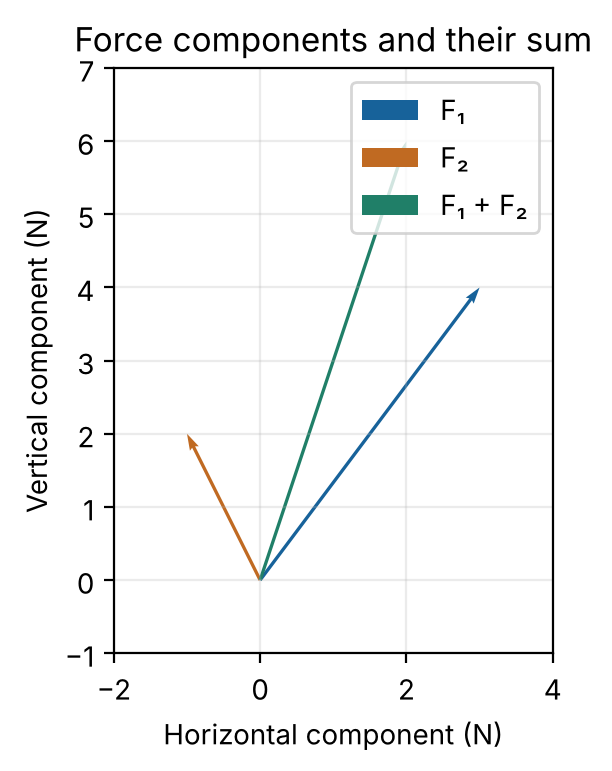

In [4]:
# Make a plotting area with equal scales so vector directions are not distorted.
fig, ax = plt.subplots()
# Draw the first force from the origin and label it.
ax.quiver(0, 0, force[0], force[1], angles='xy', scale_units='xy', scale=1, color='#17629a', label='F₁')
# Draw the second force from the origin in a contrasting colour.
ax.quiver(0, 0, second_force[0], second_force[1], angles='xy', scale_units='xy', scale=1, color='#c06a22', label='F₂')
# Draw the vector sum to connect the diagram with the computed components.
ax.quiver(0, 0, net_force[0], net_force[1], angles='xy', scale_units='xy', scale=1, color='#207f68', label='F₁ + F₂')
# Give the plot useful horizontal and vertical limits.
ax.set(xlim=(-2, 4), ylim=(-1, 7), xlabel='Horizontal component (N)', ylabel='Vertical component (N)', title='Force components and their sum')
# Make a square in the figure represent equal horizontal and vertical distances.
ax.set_aspect('equal', adjustable='box')
# Draw a light grid to help inspect arrow endpoints.
ax.grid(alpha=0.25)
# Match each coloured arrow to its physical vector; the sum is calculated from the first two.
ax.legend()
# Show the completed figure in the output cell.
plt.show()


### A loop version of a dot product

Built-in matrix operations are efficient, but a loop reveals their algorithm. The following function checks that both vectors have the same number of entries, maintains a running total, and returns one number. Parameters belong to the function's local scope. Its specification can be read without inspecting its implementation.


In [5]:
# Define a reusable dot-product function accepting two sequences of numbers.
def dot_by_loop(left, right):
    # Document the precondition and the returned scalar.
    '''Return the dot product of two equally long numeric sequences.'''
    # Reject mismatched dimensions instead of silently ignoring components.
    if len(left) != len(right):
        # Explain the shape error to whoever called this function.
        raise ValueError('Vectors must have equal numbers of components.')
    # Initialize the running sum before the first multiplication.
    total = 0.0
    # Use range(len(left)) to visit indices 0 through n-1 without stepping past the final component.
    for index in range(len(left)):
        # Accumulate left[index] * right[index]; after the last index, total equals the dot product.
        total += left[index] * right[index]
    # Return the scalar to the caller for further calculation.
    return total
# Compare the explicit algorithm with the NumPy operator.
print('Loop dot product:', dot_by_loop(force, displacement))
# Check both the known answer and the array-based implementation.
assert np.isclose(dot_by_loop(force, displacement), force @ displacement)


Loop dot product: 10.0


**Pause and predict.** What is `dot_by_loop([1, 2, 3], [4, 5, 6])`? What will happen if the second list has only two entries? The loop performs $n$ multiplications for $n$ components, so the amount of work grows approximately as $O(n)$. Try the two calls before reading on; the answers appear near the end.


## 2. Matrices: an organised table of coefficients

A matrix has rows and columns. We write its *shape* as `(number of rows, number of columns)`. For example,

$$A=\begin{bmatrix}2&1\\1&3\end{bmatrix},\qquad \mathbf{x}=\begin{bmatrix}1\\2\end{bmatrix},\qquad A\mathbf{x}=\begin{bmatrix}4\\7\end{bmatrix}.$$

The first output is the dot product of the first row of $A$ with $\mathbf x$: $2(1)+1(2)=4$. The second is $1(1)+3(2)=7$. In Python, `A[0, 1]` is the first row's second entry. `A[0, :]` extracts a row; `A[:, 1]` extracts a column. A transpose exchanges rows and columns.


In [6]:
# Create a two-by-two matrix of coefficients using a nested list.
small_matrix = np.array([[2.0, 1.0], [1.0, 3.0]])
# Store one value per matrix column so a two-column matrix can act on this input vector.
small_input = np.array([1.0, 2.0])
# Extract one number using a row index followed by a column index.
first_row_second_entry = small_matrix[0, 1]
# Select the complete first row by keeping every column.
first_row = small_matrix[0, :]
# Select the complete second column by keeping every row.
second_column = small_matrix[:, 1]
# Multiply the matrix by the vector using the matrix-product operator.
small_output = small_matrix @ small_input
# Display shape and selected entries to make indexing visible.
print('Shape:', small_matrix.shape, '; A[0,1]:', first_row_second_entry)
# Compare a row slice with a column slice; both have shape (2,) here but select different entries.
print('First row:', first_row, '; second column:', second_column)
# Display the matrix output and the transposed shape.
print('A @ x:', small_output, '; shape of A.T:', small_matrix.T.shape)
# Verify the calculation against an independent hand result.
assert np.array_equal(small_output, np.array([4.0, 7.0]))


Shape: (2, 2) ; A[0,1]: 1.0
First row: [2. 1.] ; second column: [1. 3.]
A @ x: [4. 7.] ; shape of A.T: (2, 2)


The distinction between `*` and `@` is especially important for matrices. `A * B` multiplies entries in matching positions. `A @ B` performs a matrix product, summing over a shared inner index. For an $m\times n$ matrix and an $n$-component vector, the result has $m$ components. With incompatible inner dimensions, a matrix product is undefined.


In [7]:
# Create a second two-by-two matrix for contrasting two operations.
other_matrix = np.array([[1.0, 2.0], [0.0, 1.0]])
# Multiply matching entries without combining rows and columns.
entrywise = small_matrix * other_matrix
# Form the true matrix product by combining rows with columns.
matrix_product = small_matrix @ other_matrix
# Show that the resulting matrices are different despite equal shapes.
print('Entrywise A * B:', entrywise)
# Show the matrix product below the elementwise result.
print('Matrix product A @ B:', matrix_product)
# Check an entry that differs under the two definitions.
assert entrywise[0, 1] == 2.0 and matrix_product[0, 1] == 5.0


Entrywise A * B: [[2. 2.]
 [0. 3.]]
Matrix product A @ B: [[2. 5.]
 [1. 5.]]


### Matrix–vector multiplication with explicit loops

The outer loop visits rows; the inner loop computes one row's dot product. This is useful for understanding `@`, though NumPy's implementation should be used for large arrays. A dimension check prevents an indexing error from appearing halfway through the calculation. Each result is appended to an ordinary Python list.


In [8]:
# Define a transparent implementation of the matrix–vector operation.
def matvec_by_loops(matrix, vector):
    # State the required input format and shape relationship.
    '''Multiply a rectangular list of rows by a matching vector.'''
    # Reject a matrix without rows or one whose first row has no entries.
    if not matrix or not matrix[0]:
        # Raise an informative error before trying to access any entries.
        raise ValueError('The matrix must have at least one nonempty row.')
    # Read the expected number of columns from the first row.
    column_count = len(matrix[0])
    # Check both the vector length and every row length.
    if len(vector) != column_count or any(len(row) != column_count for row in matrix):
        # Reject mismatched or ragged input as an invalid matrix product.
        raise ValueError('Matrix rows and vector must have matching lengths.')
    # Prepare a Python list for the output values.
    result = []
    # Process each row independently, preserving its order.
    for row in matrix:
        # Compute one row's dot product and append the resulting scalar.
        result.append(dot_by_loop(row, vector))
    # Return the output components as a list.
    return result
# Apply the loop algorithm to the same small example as NumPy.
loop_output = matvec_by_loops([[2, 1], [1, 3]], [1, 2])
# Print the result so it can be checked against the algebra above.
print('Loop matrix–vector result:', loop_output)
# Confirm agreement with the independently calculated NumPy result.
assert np.allclose(loop_output, small_output)


Loop matrix–vector result: [4.0, 7.0]


**Pause and predict.** What shape and values result from multiplying a $3\times2$ matrix by a two-component vector? Try `matvec_by_loops([[1,0],[0,1],[1,1]], [4,5])`. Then call it with `[4]` to observe a meaningful error. A $3\times2$ matrix contains six coefficient entries; the loop performs one multiplication for each, giving $O(mn)$ arithmetic for an $m\times n$ dense matrix.


## 3. Simultaneous equations and a two-unknown warm-up

Consider $2x+y=5$ and $x+3y=6$. Collecting coefficients gives

$$\begin{bmatrix}2&1\\1&3\end{bmatrix}\begin{bmatrix}x\\y\end{bmatrix}=\begin{bmatrix}5\\6\end{bmatrix}.$$

Eliminating $y$ by hand gives $x=9/5=1.8$ and $y=7/5=1.4$. A system with a unique solution has one vector that satisfies *all* its equations simultaneously. We use `np.linalg.solve(A, b)` for a square system and check that `A @ solution` recovers `b`. Computing `np.linalg.inv(A) @ b` is unnecessary for this purpose and is generally less desirable numerically.


In [9]:
# Store the coefficients of the two simultaneous equations.
warmup_A = np.array([[2.0, 1.0], [1.0, 3.0]])
# Put the constants 5 and 6 on the right of the equations in the same order as the matrix rows.
warmup_b = np.array([5.0, 6.0])
# Solve A x = b directly; explicitly forming an inverse is unnecessary for this calculation.
warmup_x = np.linalg.solve(warmup_A, warmup_b)
# Substitute the computed solution back into the original equations.
warmup_residual = warmup_A @ warmup_x - warmup_b
# Display the unknowns and each equation's numerical discrepancy.
print('x, y =', warmup_x)
# Display a residual that should be close to zero in floating-point arithmetic.
print('Residuals:', warmup_residual)
# Check the independently derived exact rational solution within a tolerance.
assert np.allclose(warmup_x, [9/5, 7/5], atol=tolerance)


x, y = [1.8 1.4]
Residuals: [ 0.0000000e+00 -8.8817842e-16]


## 4. Engineering model: steady temperature in a bar

Imagine a uniform slender bar with temperatures fixed at its left and right ends. We divide it into **four equal segments**, giving five positions $x_0,x_1,x_2,x_3,x_4$. The end values $T_0=100$ °C and $T_4=20$ °C are known; the three interior temperatures $T_1,T_2,T_3$ are unknown. We assume steady conditions, equal spacing, uniform material, one-dimensional conduction, and no internal heat generation. These assumptions are part of the model, not properties supplied by Python.

At each interior node the steady finite-difference balance is

$$-T_{i-1}+2T_i-T_{i+1}=0,\qquad i=1,2,3.$$

For $i=1$, substitute $T_0=100$: $2T_1-T_2=100$. At $i=2$, $-T_1+2T_2-T_3=0$. At $i=3$, substitute $T_4=20$: $-T_2+2T_3=20$. Thus

$$\underbrace{\begin{bmatrix}2&-1&0\\-1&2&-1\\0&-1&2\end{bmatrix}}_{A}
\underbrace{\begin{bmatrix}T_1\\T_2\\T_3\end{bmatrix}}_{\mathbf T}
=\underbrace{\begin{bmatrix}100\\0\\20\end{bmatrix}}_{\mathbf b}.$$

Notice that boundary temperatures appear on the **right-hand side** after the known terms are moved out of the unknown-temperature vector. A common semantic error is to leave these values out of `b` while still obtaining a mathematically valid array.


In [10]:
# Store the left fixed boundary temperature in degrees Celsius.
left_boundary = 100.0
# Store the right fixed boundary temperature in degrees Celsius.
right_boundary = 20.0
# Store descriptive physical properties without putting them into the already scaled equations.
bar_info = {'material': 'uniform illustrative bar', 'segments': 4, 'state': 'steady'}
# Set the coefficient matrix from the three written interior balance equations.
thermal_A = np.array([[2.0, -1.0, 0.0], [-1.0, 2.0, -1.0], [0.0, -1.0, 2.0]])
# Move each known boundary value to the right-hand side of its adjacent equation.
thermal_b = np.array([left_boundary, 0.0, right_boundary])
# Display the dictionary's named properties and the matrix shape.
print('Model:', bar_info, '; matrix shape:', thermal_A.shape)
# Display the system exactly as it is passed to the solver.
print('A =', thermal_A)
# Display the boundary contributions in the right-hand-side vector.
print('b =', thermal_b)
# Verify the chosen discretization has three unknowns and three equations.
assert thermal_A.shape == (3, 3) and thermal_b.shape == (3,)


Model: {'material': 'uniform illustrative bar', 'segments': 4, 'state': 'steady'} ; matrix shape: (3, 3)
A = [[ 2. -1.  0.]
 [-1.  2. -1.]
 [ 0. -1.  2.]]
b = [100.   0.  20.]


The matrix is symmetric: `A.T` equals `A`. Its off-diagonal $-1$ entries connect neighbouring interior positions. Here the equal spacing and constant conductivity allow a common physical factor to cancel from every balance equation; this does **not** mean that conductivity is unimportant for heat flux. A model with changing material or heat sources would need a different coefficient construction. We solve only the explicitly stated model.


In [11]:
# Solve all three coupled balance equations at once instead of calculating each node independently.
interior_temperature = np.linalg.solve(thermal_A, thermal_b)
# Multiply the matrix by the solution to reconstruct the right-hand side.
reconstructed_b = thermal_A @ interior_temperature
# Compute each equation's signed residual in the scaled balance equations.
thermal_residual = reconstructed_b - thermal_b
# Compute the largest absolute discrepancy, rather than comparing floats with ==.
largest_residual = np.max(np.abs(thermal_residual))
# Print each interior temperature in its physical order.
for index, value in enumerate(interior_temperature, start=1):
    # Associate the one-based physical node label with its temperature.
    print(f'T{index} = {value:.6f} °C')
# Print the equation residual and a compact measure of its size.
print('Residual:', thermal_residual, '; maximum absolute residual:', largest_residual)
# Check the analytically expected linear interpolation 80, 60, 40 °C.
assert np.allclose(interior_temperature, [80.0, 60.0, 40.0], atol=tolerance)
# Check that all equations are satisfied within a reasonable numerical tolerance.
assert largest_residual < tolerance


T1 = 80.000000 °C
T2 = 60.000000 °C
T3 = 40.000000 °C
Residual: [ 0.00000000e+00  7.10542736e-15 -1.42108547e-14] ; maximum absolute residual: 1.4210854715202004e-14


The predicted profile is linear: each step to the right reduces temperature by 20 °C. This is an **independent physical check** for the assumed uniform bar without heat generation. A tiny residual by itself shows that the *coded equations* were solved; it cannot prove that those equations correctly describe the intended physical system. Checking the boundary values, the trend, and the coefficients matters too.

The following plot includes both fixed boundaries and all three computed interior values. The horizontal axis is a node index rather than a length in metres, because no physical bar length was specified.


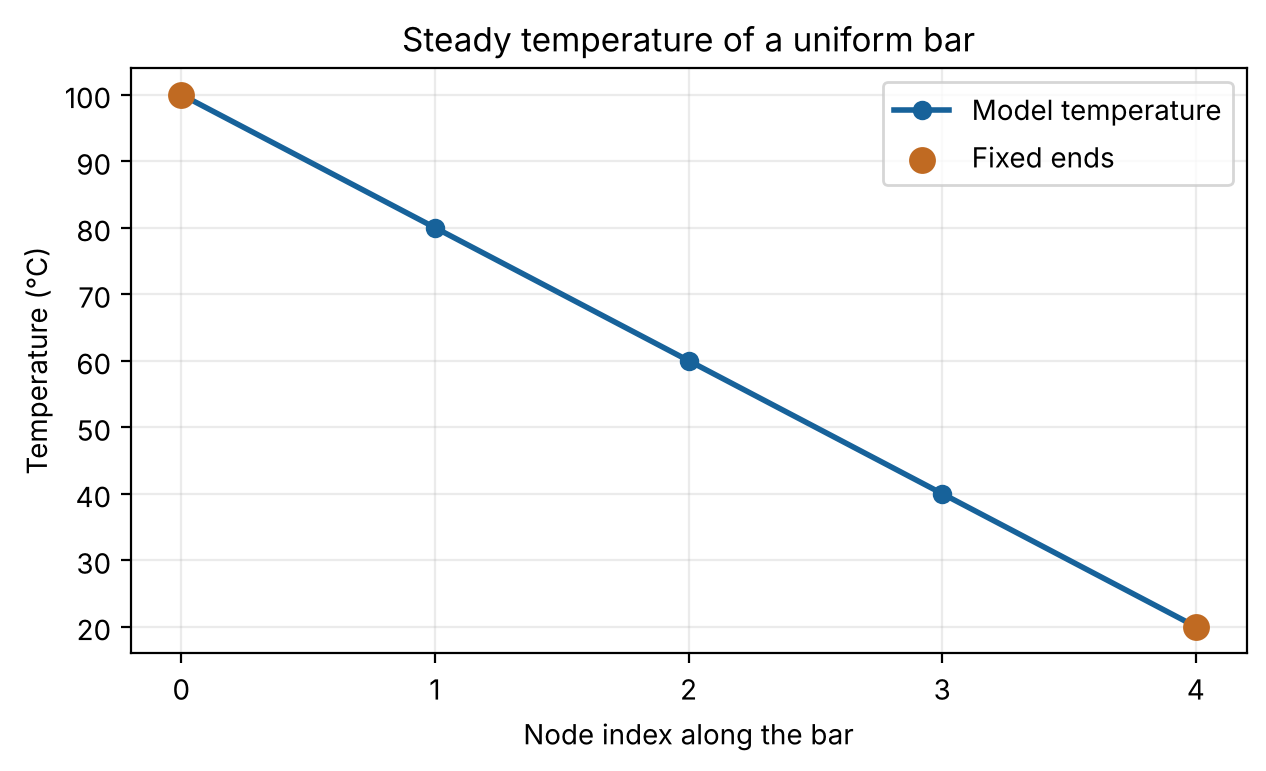

In [12]:
# Number the five positions including both fixed ends.
node_index = np.arange(5)
# Combine known boundaries and computed interior values in physical order.
complete_temperature = np.concatenate(([left_boundary], interior_temperature, [right_boundary]))
# Open a plot of temperature against the discrete position along the bar.
fig, ax = plt.subplots()
# Connect the five nodes to show the steady profile.
ax.plot(node_index, complete_temperature, 'o-', color='#17629a', linewidth=2, label='Model temperature')
# Mark the known boundary temperatures with a contrasting symbol.
ax.scatter([0, 4], [left_boundary, right_boundary], color='#c06a22', s=75, zorder=3, label='Fixed ends')
# State the physical quantity and clarify that position is an index.
ax.set(xlabel='Node index along the bar', ylabel='Temperature (°C)', title='Steady temperature of a uniform bar', xticks=node_index)
# Make the numeric trend easier to judge.
ax.grid(alpha=0.25)
# Label the model profile and the two boundary markers.
ax.legend()
# Render the completed figure within the notebook.
plt.show()


### Reusable boundary-condition function

The matrix stays the same if only the end temperatures change. A function makes that distinction explicit: its parameters are boundary values; the solution is a returned vector. We validate numeric input and avoid modifying a global right-hand side. The function then supports a simple sensitivity experiment.


In [13]:
# Encapsulate the fixed three-interior-node model for reuse.
def solve_three_node_bar(left, right):
    # Describe the values and the three returned interior temperatures.
    '''Return steady interior temperatures for a uniform four-segment bar.'''
    # Reject inputs that cannot represent finite numerical boundary values.
    if not np.isfinite(left) or not np.isfinite(right):
        # Raise an error rather than passing nonsensical data to the solver.
        raise ValueError('Boundary temperatures must be finite numbers.')
    # Construct a fresh right-hand-side vector using the two boundaries.
    rhs = np.array([float(left), 0.0, float(right)])
    # Solve the same three balance equations and return the new temperatures.
    return np.linalg.solve(thermal_A, rhs)
# Change only the right end and calculate the resulting interior temperatures.
cooler_case = solve_three_node_bar(100.0, 0.0)
# Restore the original boundaries to verify that function calls are independent.
original_case = solve_three_node_bar(100.0, 20.0)
# Print the two profiles in order for a straightforward comparison.
print('Right end at 0 °C:', cooler_case)
# Show that the original conditions reproduce the earlier result.
print('Right end at 20 °C:', original_case)
# Verify the analytic step of 25 °C when boundaries are 100 and 0 °C.
assert np.allclose(cooler_case, [75.0, 50.0, 25.0], atol=tolerance)


Right end at 0 °C: [75. 50. 25.]
Right end at 20 °C: [80. 60. 40.]


### Boundary and error checks

Testing a program means more than testing the one example it was built for. If both ends have the same temperature, the uniform no-source bar should have that temperature everywhere. If a boundary is not finite, the function should reject it. We also catch a deliberate shape error to illustrate how an exception points to a violated precondition.


In [14]:
# Calculate the equal-boundary case as a simple physical limiting case.
equal_boundary_case = solve_three_node_bar(35.0, 35.0)
# Verify all three interior temperatures equal both boundaries.
assert np.allclose(equal_boundary_case, [35.0, 35.0, 35.0], atol=tolerance)
# Print the limiting-case result for independent inspection.
print('Equal ends at 35 °C:', equal_boundary_case)
# Deliberately test a vector of the wrong length in the explicit matrix routine.
try:
    # Pass one entry to a two-column matrix to trigger its precondition.
    matvec_by_loops([[1, 2]], [3])
# Catch only the error type that the function intentionally raises.
except ValueError as error:
    # Display the explanatory error without interrupting Run All.
    print('Expected dimension error:', error)
# Fail the demonstration if a wrong-shaped input was accepted.
else:
    # Identify the missing error as a failed test of the function.
    raise AssertionError('Mismatched dimensions should have failed.')


Equal ends at 35 °C: [35. 35. 35.]
Expected dimension error: Matrix rows and vector must have matching lengths.


### Build the bar equations for any number of interior nodes

So far we typed the three-node matrix by hand. That is fine for checking the mathematics, but it becomes tedious when the number of interior nodes changes. We can turn the pattern in the balance equation into an **algorithm**. For each interior node, place `2` on the matrix diagonal, place `-1` beside it when a neighbouring interior node exists, then add the known boundary temperatures to the first and last entries of the right-hand side.

For two interior nodes, predict the result before running the code: $A=\begin{bmatrix}2&-1\\-1&2\end{bmatrix}$ and $\mathbf b=(T_{\mathrm L},T_{\mathrm R})^T$. For **one** interior node, both boundaries contribute to the *same* entry: $2T_1=T_{\mathrm L}+T_{\mathrm R}$. The latter case is a useful test of the loop and boundary handling.

We keep the assumptions of equal spacing, uniform conductivity, fixed end temperatures, and no sources. `n` counts only the *unknown interior* temperatures. The matrix uses $n^2$ stored numbers when represented as a dense NumPy array, even though most entries are zero. This explicit construction is chosen for learning; large scientific codes use sparse matrices.

**Checkpoint after the two code cells.** With one interior node and ends at 100 and 20 °C, the equation is $2T_1=120$ and the result is 60 °C. With three interior nodes, the generated matrix and right-hand side should exactly match the earlier hand-written system. For five interior nodes, the result should decrease by the same amount at every step. If any test fails, inspect the loop bounds and the two boundary additions first.


In [15]:
# Define a reusable builder for the linear system with n interior temperatures.
def build_bar_system(n, left, right):
    # State the parameters and the shapes of both returned arrays.
    """Return (A, b) for n interior nodes of a uniform, no-source bar."""
    # Reject a Boolean and other values that are not positive integer node counts.
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        # Explain which input condition failed instead of allowing a cryptic array error.
        raise ValueError('n must be a positive integer')
    # Reject temperatures that cannot be represented as finite numerical values.
    if not np.isfinite(left) or not np.isfinite(right):
        # Name the invalid boundary condition for the caller.
        raise ValueError('boundary temperatures must be finite')
    # Allocate one row per balance equation and one column per unknown interior temperature.
    matrix = np.zeros((n, n), dtype=float)
    # Allocate one known term per equation; boundary contributions will be added after the loop.
    rhs = np.zeros(n, dtype=float)
    # Visit each equation using its zero-based row index.
    for row in range(n):
        # The central 2 comes from 2 T_i in the discrete steady heat balance.
        matrix[row, row] = 2.0
        # Check whether the neighbour to the left is another unknown.
        if row > 0:
            # Place -1 immediately left of the diagonal for the neighbouring unknown T_(i-1).
            matrix[row, row - 1] = -1.0
        # Check whether the neighbour to the right is another unknown.
        if row < n - 1:
            # Place -1 immediately right of the diagonal for the neighbouring unknown T_(i+1).
            matrix[row, row + 1] = -1.0
    # Add T_left to the first right-hand-side entry after moving -T_left across the equals sign.
    rhs[0] += left
    # Add T_right to the last entry; for n=1 this is also entry zero, so both ends contribute.
    rhs[-1] += right
    # Return two objects as a tuple for the caller to unpack.
    return matrix, rhs

# Build the same three-node system that was written out earlier.
built_A, built_b = build_bar_system(3, left_boundary, right_boundary)
# Check every coefficient and boundary contribution against the hand-built system.
assert np.array_equal(built_A, thermal_A) and np.array_equal(built_b, thermal_b)
# Display the one-node case to expose the two contributions to one equation.
print('One-node system:', build_bar_system(1, 100.0, 20.0))

One-node system: (array([[2.]]), array([120.]))


**Test several sizes.** For $n$ unknowns between boundaries $T_{\mathrm L}$ and $T_{\mathrm R}$, the expected temperature at interior position $j$ is $T_{\mathrm L}+j(T_{\mathrm R}-T_{\mathrm L})/(n+1)$. This independent linear profile checks both the matrix construction and the solve. The loop below covers the smallest case as well as several larger ones. It also tests invalid input, because a function should fail clearly when its stated precondition is violated.

In [16]:
# Try one, two, three, and five interior nodes rather than one favoured input.
for node_count in (1, 2, 3, 5):
    # Construct the equations for fixed ends at 100 and 20 degrees Celsius.
    matrix, rhs = build_bar_system(node_count, 100.0, 20.0)
    # Solve the system once its dimensions agree.
    computed = np.linalg.solve(matrix, rhs)
    # Enumerate the interior physical positions from 1 through node_count.
    positions = np.arange(1, node_count + 1)
    # Independently calculate linear interpolation at those positions.
    expected = 100.0 + positions * (20.0 - 100.0) / (node_count + 1)
    # Print both the size and the temperatures for inspection.
    print(f'{node_count} interior node(s):', np.round(computed, 5))
    # Check numerical agreement rather than comparing floats with ==.
    assert np.allclose(computed, expected, atol=tolerance)
# Try an invalid node count to check the documented precondition.
try:
    # Zero unknown interior nodes are outside the function's accepted range.
    build_bar_system(0, 100.0, 20.0)
# Catch the specific input error expected from the function.
except ValueError as error:
    # Explain why the demonstration failed in the intended way.
    print('Expected input error:', error)
# Treat silent acceptance as a failed test.
else:
    # Raise an error so Run All reveals the faulty validation.
    raise AssertionError('n=0 should be rejected')

1 interior node(s): [60.]
2 interior node(s): [73.33333 46.66667]
3 interior node(s): [80. 60. 40.]
5 interior node(s): [86.66667 73.33333 60.      46.66667 33.33333]
Expected input error: n must be a positive integer


## 5. Eigenvalues, eigenvectors, and an eigensystem

In a matrix–vector product, the output generally points in a new direction. An **eigenvector** is a nonzero vector whose direction does not change when multiplied by a square matrix $A$. Its **eigenvalue** is the multiplying factor:

$$A\mathbf v=\lambda\mathbf v,\qquad \mathbf v\ne\mathbf 0.$$

The complete set of eigenvalues and associated eigenvectors is an **eigensystem**. A negative eigenvalue would reverse direction; an eigenvalue of zero would send an eigenvector to zero. Multiplying an eigenvector by any nonzero constant (including $-1$) gives another eigenvector for the same eigenvalue, so its overall sign is not physically significant.

### A two-component calculation by hand

First consider $B=\begin{bmatrix}2&-1\\-1&2\end{bmatrix}$. Try the vectors $\mathbf v_1=(1,1)^T$ and $\mathbf v_2=(1,-1)^T$:

$$B\mathbf v_1=(1,1)^T=1\mathbf v_1,\qquad
B\mathbf v_2=(3,-3)^T=3\mathbf v_2.$$

Thus the eigenvalues are **1 and 3**. These two vectors are perpendicular because their dot product is zero. NumPy returns unit-length versions of them; it may choose either sign. Predict the products before running the next cell. This example revisits lists of components, `@` for a matrix product, `for` loops, indices, and approximate floating-point comparisons.

In [17]:
# Build the symmetric two-by-two example from the hand calculation.
example_B = np.array([[2.0, -1.0], [-1.0, 2.0]])
# Ask for eigenvalues and unit-length eigenvectors of a real symmetric matrix.
example_values, example_vectors = np.linalg.eigh(example_B)
# Report the eigenvalues in the ascending order returned by eigh.
print('Eigenvalues of B:', example_values)
# Visit each eigenvector, which is stored in a COLUMN of the returned array.
for mode_index in range(len(example_values)):
    # Select the current eigenvalue using its zero-based index.
    eigenvalue = example_values[mode_index]
    # Select the corresponding COLUMN rather than a row.
    eigenvector = example_vectors[:, mode_index]
    # Multiply by the matrix to test the left side of the defining equation.
    left_side = example_B @ eigenvector
    # Scale the vector by its eigenvalue to test the right side.
    right_side = eigenvalue * eigenvector
    # Print both sides so their matching components can be inspected.
    print(f'Mode {mode_index + 1}: lambda={eigenvalue:.6f}, v={eigenvector}, Bv={left_side}')
    # Check numerical agreement without requiring exact equality of floats.
    assert np.allclose(left_side, right_side, atol=tolerance)
# Check the two hand-calculated eigenvalues, regardless of vector signs.
assert np.allclose(example_values, [1.0, 3.0], atol=tolerance)
# Check that the returned columns are orthonormal: Q-transpose times Q is I.
assert np.allclose(example_vectors.T @ example_vectors, np.eye(2), atol=tolerance)

Eigenvalues of B: [1. 3.]
Mode 1: lambda=1.000000, v=[-0.70710678 -0.70710678], Bv=[-0.70710678 -0.70710678]
Mode 2: lambda=3.000000, v=[-0.70710678  0.70710678], Bv=[-2.12132034  2.12132034]


### Write a reusable eigenpair check

`np.linalg.eigh` returns a proposed eigenvalue and eigenvector. We can test the defining equation ourselves. The function below checks shapes and rejects the zero vector. It then normalizes the vector before computing $\|A\mathbf v-\lambda\mathbf v\|_2$, so merely multiplying a proposed vector by a large number does not change the scale of this check. It returns a **tuple** containing a Boolean and the residual size; the Boolean compares that size with a chosen tolerance. For large or badly scaled matrices, a relative residual would be more appropriate.

This is a compact example of a function contract, tuples, input validation and exception handling, and tests with both valid and invalid cases. A small residual establishes that the *coded* matrix has an eigenpair; it does not validate the underlying heat-conduction model.

In [18]:
# Define a checker that accepts a square matrix, scalar, and nonzero vector.
def check_eigenpair(matrix, value, vector, atol=1e-10):
    # Document the two returned values and the absolute residual convention.
    """Return (is_valid, residual_norm) for A v = value v."""
    # Convert the proposed matrix to a numerical NumPy array.
    A = np.asarray(matrix, dtype=float)
    # Convert the proposed eigenvector to a one-dimensional numerical array.
    v = np.asarray(vector, dtype=float)
    # Require a square two-dimensional matrix and a matching vector length.
    if A.ndim != 2 or A.shape[0] != A.shape[1] or v.shape != (A.shape[0],):
        # Report an input shape mistake before attempting matrix multiplication.
        raise ValueError('A must be square and v must have matching length')
    # Check that the proposed matrix, value, and vector are finite.
    if not np.all(np.isfinite(A)) or not np.isfinite(value) or not np.all(np.isfinite(v)):
        # Reject NaN and infinity rather than mistaking them for eigenpairs.
        raise ValueError('A, value, and v must be finite')
    # Calculate the Euclidean magnitude of the candidate vector.
    magnitude = np.linalg.norm(v)
    # Exclude the zero vector from the definition of an eigenvector.
    if magnitude == 0.0:
        # Tell the caller why the candidate is invalid.
        raise ValueError('the zero vector is not an eigenvector')
    # Reject a negative or non-finite tolerance because it cannot define a meaningful residual threshold.
    if not np.isfinite(atol) or atol < 0.0:
        # Tell the caller that the absolute threshold must be a finite number at least zero.
        raise ValueError('atol must be finite and non-negative')
    # Divide by the magnitude: v and 10v describe the same eigenvector direction and should give the same test.
    unit_v = v / magnitude
    # Calculate the difference between the two sides of the defining equation.
    difference = A @ unit_v - value * unit_v
    # Take the Euclidean length of A v - lambda v; an exact eigenpair would give zero.
    residual = np.linalg.norm(difference)
    # Return both the pass/fail decision and the actual diagnostic quantity.
    return bool(residual <= atol), float(residual)

# Check the hand-calculated eigenpair for the two-by-two example.
good_pair = check_eigenpair(example_B, 1.0, [1.0, 1.0])
# Deliberately pair the same vector with the wrong eigenvalue.
wrong_value = check_eigenpair(example_B, 3.0, [1.0, 1.0])
# Display both outcomes to compare their residual sizes.
print('Correct pair:', good_pair, '; wrong eigenvalue:', wrong_value)
# Assert the expected truth values, not only the printed messages.
assert good_pair[0] and not wrong_value[0]
# Repeat with a rescaled vector to demonstrate the normalization step.
assert check_eigenpair(example_B, 1.0, [-10.0, -10.0])[0]

Correct pair:

 (True, 0.0) ; wrong eigenvalue: (False, 1.9999999999999998)


In [19]:
# Collect two invalid candidates with labels for a small parameterized test.
invalid_pairs = [('zero vector', [0.0, 0.0]), ('wrong length', [1.0, 1.0, 1.0])]
# Test each invalid candidate without interrupting the remaining notebook.
for label, candidate in invalid_pairs:
    # Start an exception handler around one deliberately invalid input.
    try:
        # Ask the checker to validate the candidate against the two-by-two matrix.
        check_eigenpair(example_B, 1.0, candidate)
    # Catch ValueError specifically so an unexpected programming error still stops the notebook.
    except ValueError as error:
        # Print the test label and explanation for the failure.
        print(f'{label}: expected error: {error}')
    # Fail the test if invalid input was silently accepted.
    else:
        # Stop execution when the checker violates its input contract.
        raise AssertionError(f'{label} was not rejected')

zero vector: expected error: the zero vector is not an eigenvector
wrong length: expected error: A must be square and v must have matching length


### The three-node bar's eigensystem

Return to the coefficient matrix `thermal_A` in the steady temperature balance. It is *real and symmetric*, so `np.linalg.eigh` returns three real eigenvalues and three mutually perpendicular unit eigenvectors. We verify the defining equation for **every** column, not just trust the library result. For this particular matrix, the exact eigenvalues are $2-\sqrt 2$, $2$, and $2+\sqrt 2$.

An eigenvector here is a **pattern across the three interior nodes**, not a steady temperature profile with the earlier 100 °C and 20 °C boundary values. We add zero values at both ends only to *draw its shape*. A displayed negative component means a signed pattern, not an impossible absolute temperature. Since the steady equations were scaled by a common factor, these eigenvalues are dimensionless coefficients; they are not decay rates in seconds by themselves.

In [20]:
# Verify that the existing heat-balance matrix equals its transpose.
assert np.allclose(thermal_A, thermal_A.T, atol=tolerance)
# Calculate its eigenvalues and its eigenvectors as columns of one array.
thermal_values, thermal_vectors = np.linalg.eigh(thermal_A)
# Calculate the three exact values for this particular matrix.
expected_values = np.array([2.0 - np.sqrt(2.0), 2.0, 2.0 + np.sqrt(2.0)])
# Compare the sorted numerical values with the independently known answer.
assert np.allclose(thermal_values, expected_values, atol=tolerance)
# Check that the columns have unit length and are perpendicular to one another.
assert np.allclose(thermal_vectors.T @ thermal_vectors, np.eye(3), atol=tolerance)
# Step through each pair of eigenvalue and eigenvector.
for mode_index in range(len(thermal_values)):
    # Retrieve one eigenvalue from the ascending list.
    eigenvalue = thermal_values[mode_index]
    # Retrieve the matching eigenvector from a column of the matrix.
    eigenvector = thermal_vectors[:, mode_index]
    # Measure the largest component of A v minus lambda v.
    mode_residual = np.max(np.abs(thermal_A @ eigenvector - eigenvalue * eigenvector))
    # Display the multiplier, spatial pattern, and numerical check.
    print(f'Mode {mode_index + 1}: lambda={eigenvalue:.6f}, v={np.round(eigenvector, 5)}, residual={mode_residual:.2e}')
    # Reject a mode if the eigenvalue equation is not satisfied accurately.
    assert mode_residual < tolerance

Mode 1: lambda=0.585786, v=[-0.5     -0.70711 -0.5    ], residual=4.44e-16
Mode 2: lambda=2.000000, v=[-0.70711  0.       0.70711], residual=4.44e-16
Mode 3: lambda=3.414214, v=[ 0.5     -0.70711  0.5    ], residual=4.44e-16


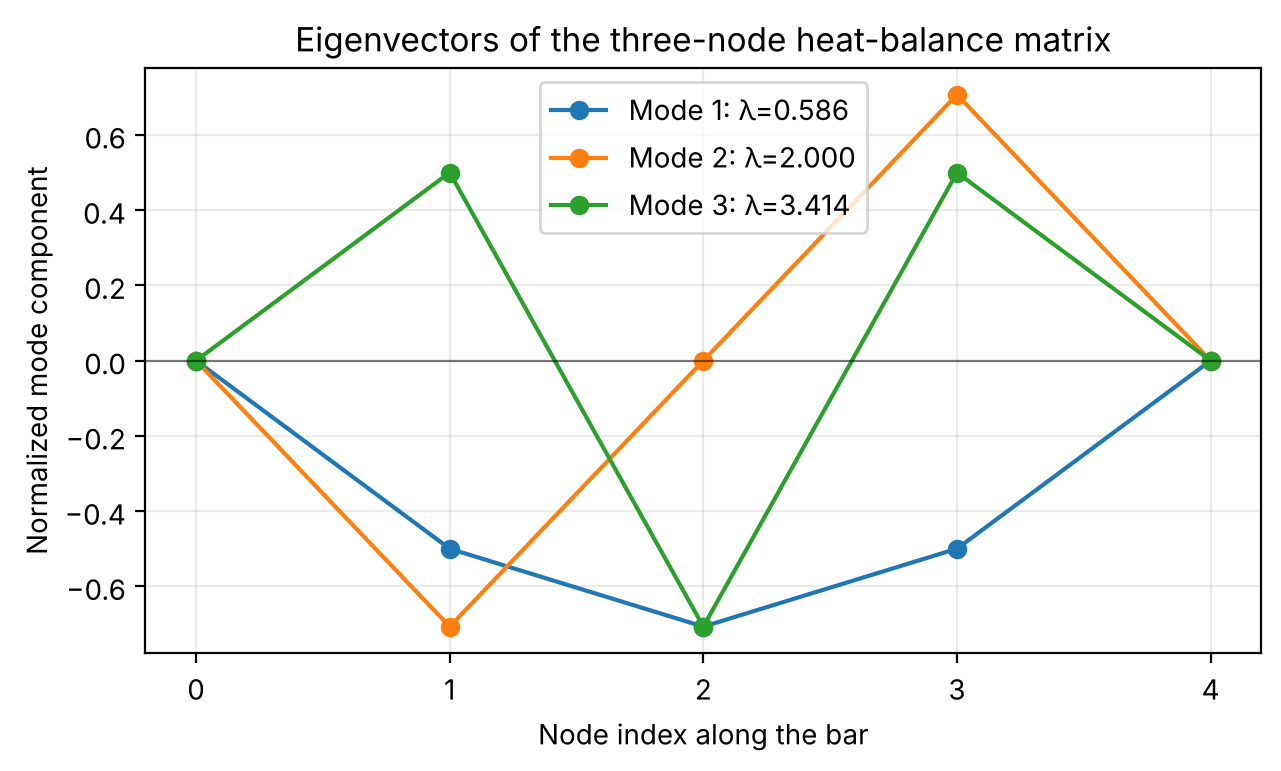

In [21]:
# Open a figure for the three independent interior-node patterns.
fig, ax = plt.subplots()
# Use one column for each mode because eigh stores the j-th eigenvector in column j.
for mode_index in range(len(thermal_values)):
    # Add zero endpoints to show the pattern's shape across all five nodes.
    pattern_with_ends = np.concatenate(([0.0], thermal_vectors[:, mode_index], [0.0]))
    # Draw and label the mode using its computed eigenvalue.
    ax.plot(node_index, pattern_with_ends, 'o-', label=f'Mode {mode_index + 1}: λ={thermal_values[mode_index]:.3f}')
# Draw zero as a reference for positive and negative signed components.
ax.axhline(0.0, color='black', linewidth=0.8, alpha=0.5)
# Describe what the axes represent and clarify that these are mode patterns.
ax.set(xlabel='Node index along the bar', ylabel='Normalized mode component', title='Eigenvectors of the three-node heat-balance matrix', xticks=node_index)
# Add a light grid to help compare the node values.
ax.grid(alpha=0.25)
# Show the eigenvalue associated with each drawn pattern.
ax.legend()
# Render the figure in the notebook output.
plt.show()

### Find and fix a row-versus-column bug

The documentation for `np.linalg.eigh` says that eigenvector $j$ is **column** `vectors[:, j]`. The next cell deliberately selects **row** `vectors[j, :]` instead. It is valid Python, so no `IndexError` occurs; this is a *semantic error*. Predict whether the eigenpair check will pass, then examine the residual and compare the two slices. The corrected selection follows in the same cell so **Run All** remains executable.

**Expected diagnostic.** The row is a valid three-component array, so Python accepts it. The residual is appreciably above the tolerance. Selecting the matching *column* makes $A\mathbf v-\lambda\mathbf v$ close to zero. This is why a successful run is weaker evidence than a mathematical check.


In [22]:
# Choose the first eigenvalue for a deliberately faulty mode check.
first_value = thermal_values[0]
# Deliberate bug: select row zero when eigenvectors are stored as columns.
wrong_pattern = thermal_vectors[0, :]
# Test the proposed pair rather than assuming the valid slice is correct.
wrong_passes, wrong_residual = check_eigenpair(thermal_A, first_value, wrong_pattern)
# Display the failure without turning the teaching bug into a notebook error.
print('Row selection passes?', wrong_passes, '; residual:', wrong_residual)
# Correct the indexing by selecting the matching eigenvector COLUMN.
correct_pattern = thermal_vectors[:, 0]
# Recheck the fixed pair using the same diagnostic function.
correct_passes, correct_residual = check_eigenpair(thermal_A, first_value, correct_pattern)
# Display the improvement in the numerical diagnostic.
print('Column selection passes?', correct_passes, '; residual:', correct_residual)
# Ensure this specific example actually reveals the intended semantic error.
assert not wrong_passes and correct_passes

Row selection passes? False ; residual: 1.732050807568877
Column selection passes? True ; residual: 6.131407058289218e-16


### Why an eigensystem helps solve this model

For a symmetric matrix, place its unit eigenvectors in the columns of $Q$ and its eigenvalues along the diagonal of $\Lambda$. Then $A=Q\Lambda Q^T$. We can express the boundary contribution $\mathbf b$ as coefficients $Q^T\mathbf b$ along the independent patterns. In $A\mathbf T=\mathbf b$, each coefficient is divided by its eigenvalue before the patterns are added back:

$$\mathbf T=Q\Lambda^{-1}Q^T\mathbf b.$$

This formula requires nonzero eigenvalues. It helps explain the calculation; for an ordinary linear system, `np.linalg.solve(A, b)` is the clearer and generally preferable computational choice. The result below should agree with the previously computed 80, 60, 40 °C. The eigenvectors' signs can change without changing the reconstructed solution.

In [23]:
# Give the matrix of eigenvectors a short mathematical name.
Q = thermal_vectors
# Project the boundary-contribution vector onto the independent modes.
mode_contributions = Q.T @ thermal_b
# Divide each projected contribution by its matching nonzero eigenvalue.
solution_contributions = mode_contributions / thermal_values
# Add the scaled modes back in physical node coordinates.
temperature_by_modes = Q @ solution_contributions
# Display the result from the eigensystem beside the direct solution.
print('Temperature from modes:', temperature_by_modes)
# Display the direct result already obtained with the linear solver.
print('Temperature from solve:', interior_temperature)
# Check the two independent computational routes give the same values.
assert np.allclose(temperature_by_modes, interior_temperature, atol=tolerance)
# Check the reconstructed temperatures still satisfy the original balances.
assert np.allclose(thermal_A @ temperature_by_modes, thermal_b, atol=tolerance)

Temperature from modes: [80. 60. 40.]
Temperature from solve: [80. 60. 40.]


**Pause and reflect.** Why is the zero vector excluded from the eigenvector definition? Which columns of `Q` describe the patterns? What does an eigenvalue of zero imply for the division in the modal formula? If NumPy reverses one eigenvector's sign, which numerical checks still pass?

**Programming connection.** `eigh` returns a tuple of two arrays; tuple unpacking names them separately. The loop checks every mode, the assertions are numerical tests, and `Q.T @ b` and `Q @ coefficients` combine earlier matrix operations. For a matrix with many rows, computing every eigenvector can cost substantially more time and memory than solving one system; use an eigensystem when its modes or spectral properties answer a real question.

### Optional programming challenge: power iteration

An eigensolver is a useful tool, but how might a program *find* one eigenpair? **Power iteration** begins with a nonzero trial vector, repeatedly multiplies it by $A$, and normalizes it. When one eigenvalue has a unique largest **absolute** value and the starting vector has a component in its direction, the direction can approach the corresponding eigenvector. A residual check gives a stopping condition. This is a guided algorithm exercise rather than a general replacement for `np.linalg.eigh`.

For the two-component matrix $B$, the method should approach eigenvalue 3. For the three-node bar, it should approach $2+\sqrt2\approx3.414$. It can converge slowly, and it can fail to find the intended mode if the start is orthogonal to that eigenvector or if dominant magnitudes are tied. We cap the loop to avoid running forever. Each dense matrix–vector multiplication takes work proportional to $n^2$ for an $n\times n$ matrix; the number of iterations also matters. For this tiny teaching problem, timing is not a meaningful performance comparison with NumPy.

In [24]:
# Define a simple power-iteration algorithm with a maximum step count.
def power_iteration(matrix, start, atol=1e-9, max_steps=100):
    # Describe the returned eigenvalue, vector, count, and diagnostic history.
    """Return (value, unit_vector, steps, residuals) for a dominant mode."""
    # Store the matrix as a floating-point array.
    A = np.asarray(matrix, dtype=float)
    # Make a float copy of the caller's start; the iteration repeatedly replaces its own v.
    v = np.array(start, dtype=float, copy=True)
    # Check that the matrix is square and the vector has the correct length.
    if A.ndim != 2 or A.shape[0] != A.shape[1] or v.shape != (A.shape[0],):
        # State the expected matrix and vector shapes before attempting a matrix–vector product.
        raise ValueError('A must be square and start must have matching length')
    # Check finite inputs, a positive tolerance, and a positive step cap.
    if not np.all(np.isfinite(A)) or not np.all(np.isfinite(v)) or not np.isfinite(atol) or atol <= 0 or not isinstance(max_steps, int) or max_steps < 1:
        # Reject inputs that make an iteration or its stopping check invalid.
        raise ValueError('inputs must be finite, atol positive, and max_steps a positive integer')
    # Find the magnitude of the trial vector before normalizing it.
    initial_size = np.linalg.norm(v)
    # Exclude a trial direction with no length.
    if initial_size == 0.0:
        # Normalizing a zero-length start would divide by zero, so ask for a nonzero trial direction.
        raise ValueError('start must be nonzero')
    # Set the initial length to one so the chosen scale of the start does not influence the direction.
    v = v / initial_size
    # Store a residual from each step so we can plot how close A v becomes to lambda v.
    residuals = []
    # Try at most max_steps updates, counting from one for readability.
    for step in range(1, max_steps + 1):
        # Multiply A by v; repeated multiplication favours the eigenmode with largest absolute eigenvalue.
        next_v = A @ v
        # Measure the length used to normalize the new direction.
        next_size = np.linalg.norm(next_v)
        # Detect the case where matrix multiplication destroys the trial direction.
        if next_size == 0.0:
            # Stop because no nonzero direction remains to normalize.
            raise ValueError('the iterate became zero')
        # Divide by the new magnitude to prevent repeated products from growing or shrinking without bound.
        v = next_v / next_size
        # For unit v, v.T @ A @ v estimates its eigenvalue; float converts NumPy's scalar for display.
        value = float(v @ (A @ v))
        # Measure how closely the proposed eigenpair satisfies A v = value v.
        residual = float(np.linalg.norm(A @ v - value * v))
        # Save one diagnostic number for this iteration.
        residuals.append(residual)
        # Stop only when the equation residual is small; exact equality is unreliable with floating-point values.
        if residual <= atol:
            # Return the result and iteration count together so the caller can check accuracy and computational work.
            return value, v, step, residuals
    # Raise a clear error if the iteration reaches the step cap without converging.
    raise RuntimeError('power iteration did not reach the requested residual tolerance')

# Apply the algorithm to the hand-checkable two-component example.
power_B = power_iteration(example_B, [1.0, 0.0])
# Apply the same function to the three-node heat-balance matrix.
power_bar = power_iteration(thermal_A, [1.0, 0.0, 0.0])
# Print the number of iterations and the estimated dominant values.
print(f'B: lambda={power_B[0]:.9f} in {power_B[2]} steps')
# Display the bar estimate separately for comparison with eigh.
print(f'Bar: lambda={power_bar[0]:.9f} in {power_bar[2]} steps')
# Compare values with the largest-magnitude values returned by eigh here.
assert np.isclose(power_B[0], example_values[-1], atol=1e-8)
# Verify the three-node estimate against its known exact eigenvalue.
assert np.isclose(power_bar[0], 2.0 + np.sqrt(2.0), atol=1e-8)
# Verify the returned vector satisfies the original eigenvalue equation.
assert check_eigenpair(thermal_A, power_bar[0], power_bar[1], atol=1e-9)[0]

B: lambda=3.000000000 in 20 steps
Bar: lambda=3.414213562 in 41 steps


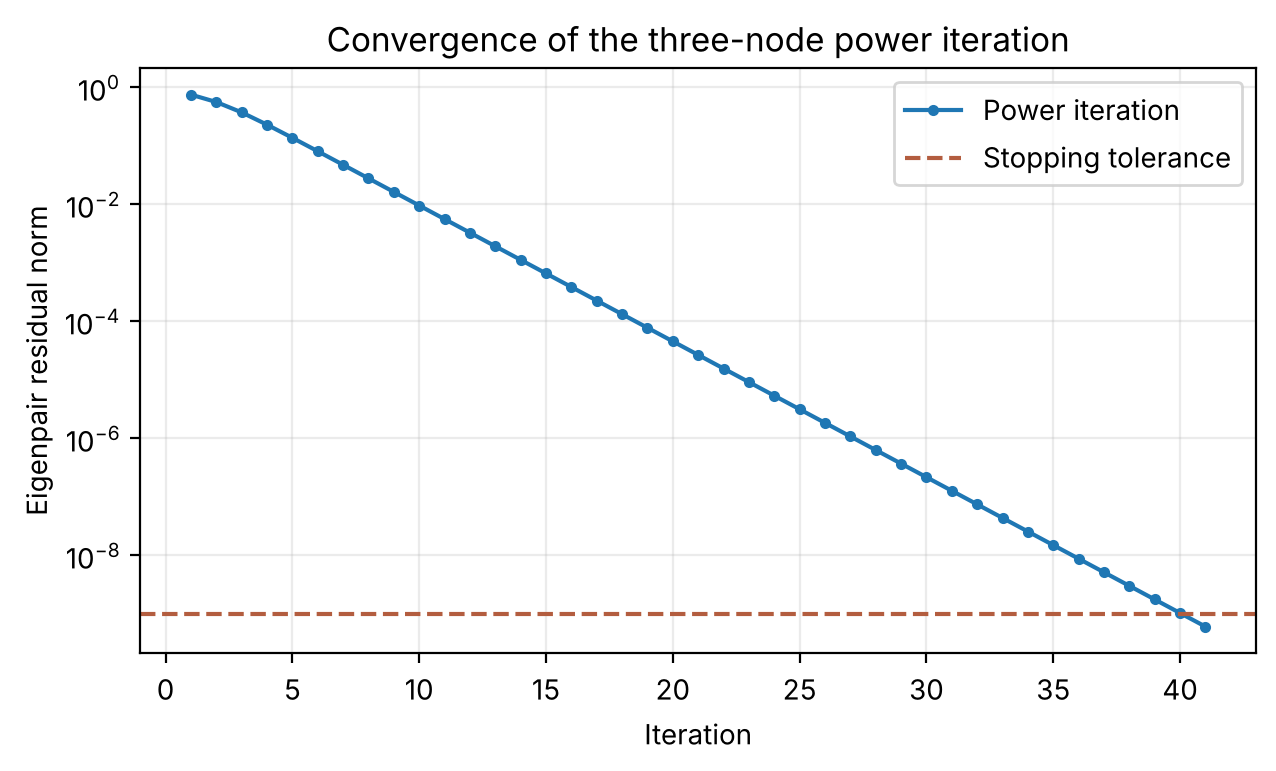

In [25]:
# Create an iteration-number axis beginning with the first update.
iteration_number = np.arange(1, power_bar[2] + 1)
# Create a plot of the residual history saved by the algorithm.
fig, ax = plt.subplots()
# Plot positive residuals on a logarithmic vertical scale to reveal convergence.
ax.semilogy(iteration_number, power_bar[3], 'o-', markersize=3, label='Power iteration')
# Mark the requested stopping tolerance with a dashed reference line.
ax.axhline(1e-9, color='#b35d3f', linestyle='--', label='Stopping tolerance')
# Describe the axes and the meaning of the convergence plot.
ax.set(xlabel='Iteration', ylabel='Eigenpair residual norm', title='Convergence of the three-node power iteration')
# Add a light grid to make changes over several orders of magnitude readable.
ax.grid(alpha=0.25)
# Identify the curve and the stopping line.
ax.legend()
# Show the completed convergence plot after setting axes and legend; its final point crosses the tolerance line.
plt.show()

**Predict and experiment.** What happens if the initial vector is already the middle eigenvector `thermal_vectors[:, 1]`? The algorithm should immediately identify its eigenpair rather than discover the dominant one, because that start has no component in the dominant direction. What happens when `max_steps=2` with a stringent tolerance? Catch the resulting `RuntimeError` if you try it. These are examples of *algorithmic assumptions* and a bounded loop, not a reason to distrust `np.linalg.eigh`.

**Read the convergence plot.** The vertical axis is logarithmic: each major step downward represents a factor of ten in the residual, not a constant subtraction. The 41st update in the supplied three-node run reaches the chosen $10^{-9}$ threshold. This iteration count depends on the matrix, starting vector, and tolerance; do not treat it as a general speed claim.


## 6. Optional extension: fit a physical relationship from measurements

Solving $A\mathbf x=\mathbf b$ above gave three exact model equations for three unknown temperatures. Experimental measurements usually contain noise. Suppose we measure extension $x$ of a spring in metres and applied force $F$ in newtons. Hooke's law suggests $F\approx kx$ for small extensions, with stiffness $k$ in N/m. For five measurements, the system $\mathbf F\approx Xk$ has **five rows but one unknown**. An exact solution generally cannot satisfy all readings. We choose $k$ to minimise the sum of squared residuals $\sum_i(kx_i-F_i)^2$.

This deliberately elementary one-parameter fit keeps attention on matrix shape and the distinction between a physical model and measurement error. `np.linalg.lstsq` returns a tuple: fitted coefficients, the sum of squared residuals in suitable cases, a rank, and singular values. We do not interpret these as a statistical uncertainty interval. Measurement uncertainty, calibration, and more complex material behaviour require further study.


In [26]:
# Store five measured spring extensions in metres.
extension = np.array([0.010, 0.020, 0.030, 0.040, 0.050])
# Store corresponding measured forces in newtons with small variations.
measured_force = np.array([1.02, 1.96, 3.04, 3.98, 5.08])
# Make a five-row, one-column design matrix from the extension vector.
design = extension.reshape(-1, 1)
# Fit the coefficient that minimises the sum of squared force residuals.
fit_coefficients, fit_sum_squares, fit_rank, fit_singular_values = np.linalg.lstsq(design, measured_force, rcond=None)
# Retrieve the first and only coefficient as the spring stiffness.
stiffness = fit_coefficients[0]
# Predict forces at the measured extensions using the fitted model.
predicted_force = design @ fit_coefficients
# Calculate measured minus predicted forces at the five positions.
force_residual = measured_force - predicted_force
# Calculate the sum of squared residuals directly as a transparent check.
direct_sum_squares = force_residual @ force_residual
# Print the matrix shape to distinguish this from a square linear system.
print('Design matrix shape:', design.shape, '; rank:', fit_rank)
# Print the fitted parameter with its physical unit.
print(f'Estimated spring stiffness: {stiffness:.2f} N/m')
# Show residuals and the sum of their squares without claiming they are zero.
print('Measured minus predicted (N):', np.round(force_residual, 4))
# Display the error measure in squared newtons.
print('Sum of squared residuals (N²):', round(direct_sum_squares, 7))
# Check that a one-parameter model was identified and outputs are consistent.
assert fit_rank == 1 and np.allclose(fit_sum_squares[0], direct_sum_squares)


Design matrix shape: (5, 1) ; rank: 1
Estimated spring stiffness: 100.69 N/m
Measured minus predicted (N): [ 0.0131 -0.0538  0.0193 -0.0476  0.0455]
Sum of squared residuals (N²): 0.0077745


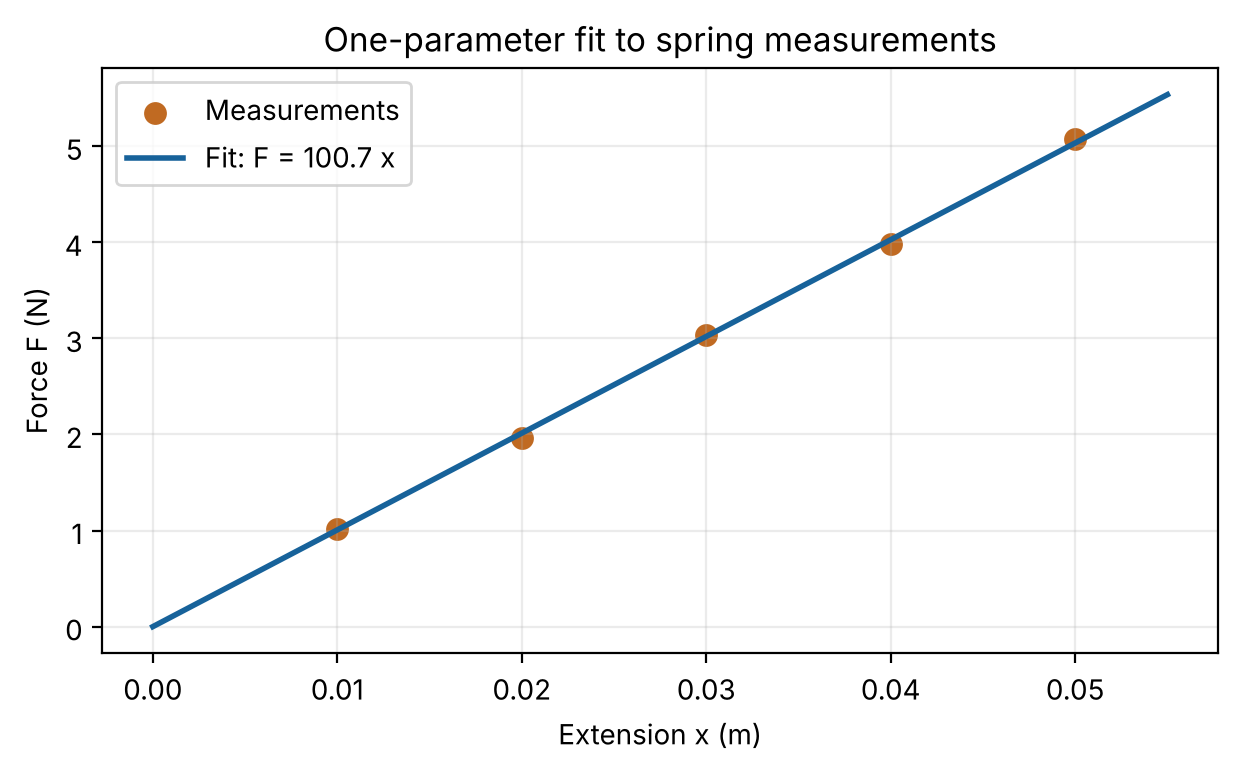

In [27]:
# Create smooth extension positions between zero and the last measurement.
extension_line = np.linspace(0.0, 0.055, 100)
# Calculate the fitted force on each smooth position.
fitted_line = stiffness * extension_line
# Open a separate figure so the fit is not confused with the bar model.
fig, ax = plt.subplots()
# Use separate points for measurements because they contain deviations from the ideal straight-line law.
ax.scatter(extension, measured_force, color='#c06a22', s=52, label='Measurements')
# Draw the one-parameter least-squares model as a line.
ax.plot(extension_line, fitted_line, color='#17629a', linewidth=2, label=f'Fit: F = {stiffness:.1f} x')
# Label metres and newtons so the fitted slope can be interpreted as a stiffness in N/m.
ax.set(xlabel='Extension x (m)', ylabel='Force F (N)', title='One-parameter fit to spring measurements')
# Distinguish the measured points from the fitted law in the legend; they need not coincide exactly.
ax.legend()
# Add a light grid to support reading approximate values.
ax.grid(alpha=0.25)
# Render both measurements and the fitted model so departures from the line can be inspected visually.
plt.show()


## 7. Optional numerical cautions

### Singular systems and nearly dependent equations

If one equation is twice another, it provides no independent information. For instance, $x+y=2$ and $2x+2y=4$ have infinitely many solutions. The corresponding square matrix is **singular**, so `np.linalg.solve` raises `LinAlgError`. A nearly singular system can still be solvable but very sensitive to changed measurements. The *condition number* estimates possible amplification of relative perturbations; it is not itself a residual.


In [28]:
# Construct two equations with proportional left-hand sides.
singular_A = np.array([[1.0, 1.0], [2.0, 2.0]])
# Give the equations compatible right-hand sides, leaving infinitely many solutions.
singular_b = np.array([2.0, 4.0])
# Attempt the square-system solver only to demonstrate its error behaviour.
try:
    # A singular matrix cannot yield a unique solution through this routine.
    np.linalg.solve(singular_A, singular_b)
# Catch the specific linear-algebra exception raised by NumPy.
except np.linalg.LinAlgError as error:
    # Explain the failure in terms of independent equations.
    print('Expected singular-system error:', error)
# Fail the example if this singular system was treated as uniquely solvable.
else:
    # Mark a missing exception as a failed diagnostic test.
    raise AssertionError('A singular square system must not return a unique solve result.')
# Evaluate the condition number of the well-behaved thermal system.
thermal_condition = np.linalg.cond(thermal_A)
# Show the number without treating it as a number of correct digits.
print('Thermal matrix condition number (2-norm):', round(thermal_condition, 3))


Expected singular-system error: Singular matrix
Thermal matrix condition number (2-norm): 5.828


### An explicit elimination algorithm (advanced optional reading)

For a small square system, Gaussian elimination combines rows to make the matrix upper triangular, then back-substitutes. At each column the code chooses a row with a large available pivot; this **partial pivoting** avoids division by zero when a better pivot is below. It is useful for seeing what a solver must do, but production work should use `np.linalg.solve`. Dense elimination requires on the order of $n^3$ operations for an $n\times n$ system; the earlier matrix–vector check uses on the order of $n^2$. This explains why it is sensible to solve only when needed and then verify with a cheaper product.


In [29]:
# Define a small pedagogical solver for a square numeric system.
def gaussian_elimination(matrix, rhs):
    # Explain that the algorithm copies inputs and uses partial pivoting.
    '''Solve a small square system by elimination and back-substitution.'''
    # Make a floating-point copy so row operations cannot change the caller's matrix.
    work = np.array(matrix, dtype=float, copy=True)
    # Make an independent floating-point copy of the right-hand side.
    values = np.array(rhs, dtype=float, copy=True)
    # Determine how many equations must be eliminated.
    n = len(values)
    # Reject wrong shapes before the first row operation.
    if work.shape != (n, n):
        # Report that the algorithm expects n equations for n unknowns.
        raise ValueError('Expected an n-by-n matrix and an n-element right-hand side.')
    # Visit each column except the last, which needs no forward elimination.
    for pivot_column in range(n - 1):
        # Partial pivoting chooses the largest remaining absolute entry to reduce division by a tiny pivot.
        pivot_row = pivot_column + np.argmax(np.abs(work[pivot_column:, pivot_column]))
        # Reject a column with no usable nonzero pivot.
        if abs(work[pivot_row, pivot_column]) < 1e-14:
            # State that the given system cannot be solved reliably by this routine.
            raise ValueError('Zero or very small pivot encountered.')
        # Exchange the chosen pivot row with the current row in the matrix.
        work[[pivot_column, pivot_row]] = work[[pivot_row, pivot_column]]
        # Exchange the corresponding right-hand-side entries as well.
        values[[pivot_column, pivot_row]] = values[[pivot_row, pivot_column]]
        # Visit each row beneath the selected pivot.
        for row in range(pivot_column + 1, n):
            # Divide the entry to eliminate by the selected pivot value.
            factor = work[row, pivot_column] / work[pivot_column, pivot_column]
            # This row operation makes the entry below the pivot zero while preserving the system's solutions.
            work[row, pivot_column:] -= factor * work[pivot_column, pivot_column:]
            # Apply the same row operation to the right-hand side.
            values[row] -= factor * values[pivot_column]
    # Reject an unusable final diagonal entry before back-substitution.
    if abs(work[-1, -1]) < 1e-14:
        # Signal that this small demonstration does not yield a unique solution.
        raise ValueError('Zero or very small final pivot encountered.')
    # Allocate one unknown per equation for the upward pass.
    solution = np.zeros(n)
    # Visit rows from bottom to top because later unknowns are then known.
    for row in range(n - 1, -1, -1):
        # Subtract the known terms to the right of the diagonal before solving for this row's unknown.
        remaining = values[row] - work[row, row + 1:] @ solution[row + 1:]
        # Divide by the current diagonal entry to obtain this unknown.
        solution[row] = remaining / work[row, row]
    # Return a fresh solution without modifying the original inputs.
    return solution
# Solve the temperature system with the educational algorithm.
manual_solution = gaussian_elimination(thermal_A, thermal_b)
# Show that the advanced method matches the standard solver for this case.
print('Elimination solution (°C):', manual_solution)
# Verify both agreement and unchanged source matrix and right-hand side.
assert np.allclose(manual_solution, interior_temperature) and thermal_A[0, 0] == 2.0 and thermal_b[0] == 100.0


Elimination solution (°C): [80. 60. 40.]


## 8. Independent practice and solutions

Try these before opening or running the answer cell. You may use a new notebook cell and the functions above.

1. Compute `dot_by_loop([1, 2, 3], [4, 5, 6])` by hand and with Python. Explain why `[4, 5]` is rejected as a second argument.
2. Calculate `matvec_by_loops([[1, 0], [0, 1], [1, 1]], [4, 5])`. State the input matrix's and output vector's shapes.
3. Predict the three interior temperatures when both ends are 50 °C. Check with `solve_three_node_bar`.
4. Predict the temperatures for fixed ends at 80 and 0 °C. Which of the three interior values equals the mean of the boundaries?
5. Change the spring's five measured forces to `[1, 2, 3, 4, 5]` N, keeping the extensions. What stiffness should a one-parameter fit return? Why are the residuals zero (apart from round-off)?
6. For $B=\begin{bmatrix}2&-1\\-1&2\end{bmatrix}$, check $B(1,1)^T$ and $B(1,-1)^T$. State both eigenvalues and explain why NumPy may print opposite eigenvector signs.
7. Use `build_bar_system(2, 90.0, 30.0)` and predict its matrix, right-hand side, and temperatures before running it.
8. Change the deliberate row-selection bug to `thermal_vectors[:, 0]` and explain why the residual shrinks.
9. Explain why the three-node temperature residual can be small even if a programmer mistakenly enters 200 °C instead of 20 °C at the right boundary.

The exercises use known or easily calculated answers. Their purpose is to practise tracing, prediction, validation, and interpretation rather than introduce a new library command.


In [30]:
# Calculate the three-component dot product in exercise 1.
exercise_one = dot_by_loop([1, 2, 3], [4, 5, 6])
# Calculate the three-row matrix–vector result in exercise 2.
exercise_two = matvec_by_loops([[1, 0], [0, 1], [1, 1]], [4, 5])
# Solve the equal-boundary case in exercise 3.
exercise_three = solve_three_node_bar(50.0, 50.0)
# Solve the unequal-boundary case in exercise 4.
exercise_four = solve_three_node_bar(80.0, 0.0)
# Display short numeric answers after students have attempted the exercises.
print('1:', exercise_one, '; 2:', exercise_two)
# Show the two physical profiles in order from left interior to right interior.
print('3:', exercise_three, '; 4:', exercise_four)
# Check the expected values independently of their displayed formatting.
assert exercise_one == 32 and exercise_two == [4.0, 5.0, 9.0]
# Check equal boundaries and a constant 20 °C drop per segment.
assert np.allclose(exercise_three, [50, 50, 50]) and np.allclose(exercise_four, [60, 40, 20])


1: 32.0 ; 2: [4.0, 5.0, 9.0]
3: [50. 50. 50.] ; 4: [60. 40. 20.]


**Interpretation of the remaining answers.** In exercise 1 the mismatched list violates the function's equal-length precondition. In exercise 2 the input shape is `(3, 2)` and the output has shape `(3,)`. In exercise 4 the central interior node is 40 °C, the mean of 80 and 0 °C. In exercise 5 the stiffness is exactly 100 N/m for the stated ideal data; a fitted line passes through every point, so its residuals vanish within floating-point precision. In exercise 9 a solver can accurately satisfy a *wrongly entered* right-hand side. Compare the coded boundary with the physical statement before trusting the result.

For exercise 6, the two products are $(1,1)^T$ and $(3,-3)^T$, so the eigenvalues are 1 and 3. Reversing an eigenvector changes both sides of $B\mathbf v=\lambda\mathbf v$ by the same sign.

For exercise 7, the matrix is $\begin{bmatrix}2&-1\\-1&2\end{bmatrix}$, the right-hand side is $(90,30)^T$, and the interior temperatures are $(70,50)^T$. For exercise 8, the eigenvectors are columns; selecting a row generally pairs the wrong pattern with the eigenvalue.

### Closing perspective

A matrix is more than a rectangular collection of numbers: its coefficients encode a model. Python can solve the resulting equations quickly, but decisions about the model, units, boundary conditions, and measurement quality remain the engineer's responsibility. The eigensystem reveals independent patterns associated with the matrix, while a direct linear solve remains the natural route for the steady temperatures. In later courses, linear algebra also appears in structural equilibrium, circuit analysis, regression, differential equations, and dynamical systems. The present examples were chosen so every numerical result has a clear physical or hand-calculated check.
